# CPM GMM validation: PCA dimensionality and subsampling stability

This notebook is a validation companion to `CPM_GMM.ipynb`. It keeps the same
Schaefer200 + Harvard-Oxford 14 ROI FC preparation, nuisance adjustment, PCA
representation, and two-component full-covariance GMM framework, but focuses
only on three prespecified robustness questions:

1. **Is the choice of 50 PCs arbitrary?**  
   Determine `k_50pct`, the minimum number of PCs required to explain at least
   50% of the FC variance, and repeat the GMM alignment analysis using PC1–PC`k_50pct`.

2. **Does the result depend on PCA dimensionality?**  
   Repeat GMM alignment across a prespecified dimensionality grid and examine
   the stability of alignment effect sizes rather than searching for the most
   significant dimension.

3. **Does the result depend on the particular participant sample?**  
   Refit the GMM in repeated stratified 80% participant subsamples of the
   prespecified PC1–PC50 representation and quantify both IAT-group alignment
   and agreement with the full-sample cluster solution.

The IAT group labels are never used to fit PCA or GMM. They are used only after
clustering to quantify cluster–group alignment.


## 0. CPU / thread configuration

In [1]:
# ============================================================
# 0. CPU / thread configuration
# ============================================================

import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

N_CPU = os.cpu_count() or 20

# Label permutation is cheap and can use more workers.
N_JOBS_PERM = max(1, min(18, N_CPU - 2))

# Subsampling repeatedly fits full-covariance GMMs. Threading is used below to
# avoid copying the participant x PC matrix into many worker processes.
N_JOBS_SUBSAMPLE = max(1, min(18, N_CPU - 2))

print(f"Detected CPU cores: {N_CPU}")
print(f"N_JOBS_PERM={N_JOBS_PERM}")
print(f"N_JOBS_SUBSAMPLE={N_JOBS_SUBSAMPLE}")


Detected CPU cores: 24
N_JOBS_PERM=18
N_JOBS_SUBSAMPLE=18


## 1. Imports

In [2]:
# ============================================================
# 1. Imports
# ============================================================

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from joblib import Parallel, delayed
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

DATA_ROOT = Path.home() / "Desktop" / "YiZhang"
SCRIPTS_DIR = Path("/Users/yiling/Documents/Codex/HBN_Cdx/Scripts")

for package_root in [DATA_ROOT, SCRIPTS_DIR]:
    if str(package_root) not in sys.path:
        sys.path.insert(0, str(package_root))

from biox.prep import compute_fc_from_timeseries_dirs
from biox.ML import (
    make_pca_embeddings,
    evaluate_binary_cluster_alignment,
    test_binary_cluster_alignment,
)
from biox.CPM_new import (
    _design_matrix,
    _residualize_with_C,
    _select_finite_variance_columns,
    _validate_array,
)

print("DATA_ROOT:", DATA_ROOT)
print("SCRIPTS_DIR:", SCRIPTS_DIR)


DATA_ROOT: /Users/fmri24/Desktop/YiZhang
SCRIPTS_DIR: /Users/yiling/Documents/Codex/HBN_Cdx/Scripts


## 2. Paths and validation parameters

The main analysis remains fixed at PC1–PC50. Validation choices are specified
independently of IAT-group alignment results:

- `VARIANCE_TARGET = 0.50` defines `k_50pct`;
- `DIMENSION_GRID = [10, 20, 30, 40, 50]` defines the dimensionality curve;
- `SUBSAMPLE_FRACTION = 0.80` and `N_SUBSAMPLES = 500` define sample-stability
  analysis.

Only the `k_50pct` sensitivity analysis receives a formal label-permutation
test. The dimensionality curve is treated as a robustness/effect-size analysis,
not as a search across multiple hypothesis tests.


In [3]:
# ============================================================
# 2. Paths and validation parameters
# ============================================================

SCALE_CSV = DATA_ROOT / "量表数据汇总_with_MeanEnorm.csv"

SCHAEFER_N_ROIS = 200
SCHAEFER_DIR = DATA_ROOT / "HBN_func_Schaefer200"
HO_DIR = DATA_ROOT / "HBN_func_HarvardOxfordSubcortical"
HO_RAW_INDEX = np.array([4, 5, 6, 7, 9, 10, 11, 15, 16, 17, 18, 19, 20, 21]) - 1

IAT_LABEL = "IAT_PCIAT_Total"
SITE_COL = "ScannerSite"
CBCL_TOTAL_COL = "CBCL,CBCL_Total_T"
MOTION_COL = "mean_enorm"

COVARIATE_COLS = [
    "Basic_Demos,Age",
    "Basic_Demos,Sex",
    "Barratt,Barratt_Total_Edu",
    "Barratt,Barratt_Total_Occ",
    "CBCL,CBCL_Int_T",
    "CBCL,CBCL_Ext_T",
    MOTION_COL,
]

EXPECTED_N_TIMEPOINTS = 740
CBCL_MAX = 70
ENORM_CUTOFF = 0.3
IAT_CUTOFF = 30

OUT_DIR = DATA_ROOT / "CPM_GMM_validation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Main model dimensionality from CPM_GMM.ipynb.
MAIN_PC_N = 50

# Validation 1: minimum number of PCs explaining >= 50% cumulative FC variance.
VARIANCE_TARGET = 0.50
N_PERM_K50 = 5000

# Validation 2: prespecified dimensionality curve.
DIMENSION_GRID = [10, 20, 30, 40, 50]

# Validation 3: participant subsampling stability.
SUBSAMPLE_FRACTION = 0.80
N_SUBSAMPLES = 500

# Same GMM specification as the main notebook.
GMM_N_COMPONENTS = 2
GMM_COVARIANCE_TYPE = "full"
GMM_N_INIT = 30
GMM_REG_COVAR = 1e-5
GMM_MAX_ITER = 1000

RANDOM_STATE = 2026

print("OUT_DIR:", OUT_DIR)
print("MAIN_PC_N:", MAIN_PC_N)
print("VARIANCE_TARGET:", VARIANCE_TARGET)
print("DIMENSION_GRID:", DIMENSION_GRID)
print("SUBSAMPLE_FRACTION:", SUBSAMPLE_FRACTION)
print("N_SUBSAMPLES:", N_SUBSAMPLES)


OUT_DIR: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation
MAIN_PC_N: 50
VARIANCE_TARGET: 0.5
DIMENSION_GRID: [10, 20, 30, 40, 50]
SUBSAMPLE_FRACTION: 0.8
N_SUBSAMPLES: 500


## 3. FC calculation

This section is intentionally kept aligned with `CPM_GMM.ipynb` so that the
validation analyses operate on exactly the same FC definition and participant
inputs as the main connectomic-differentiation analysis.


In [4]:
# ============================================================
# 3. FC 计算 / 数据读取
# ============================================================

# 1) 读取量表总表。df_raw 是原始表型表；df_fc 是成功计算 FC 的被试表，
#    与 FC_all 严格按行对齐。
df_raw = pd.read_csv(SCALE_CSV)
df_raw["ID"] = df_raw["ID"].astype(str)

# 2) 用 roi_timeseries_sources 描述不同 atlas/parcellation 的 ROI time series 来源。
#    这里的“来源”不是 atlas 图谱文件本身，而是已经提前提取好的 .npy
#    time series 目录。每个来源可以指定自己的 run_labels 和 ROI subset。
#
#    - Schaefer200：cortical atlas，读取全部 200 个 cortical ROI；
#    - HO14：subcortical atlas，读取 HO_DIR 中的 time series，并只保留
#      HO_RAW_INDEX 指定的 14 个 subcortical ROI。
#
#    compute_fc_from_timeseries_dirs() 会对每个被试执行：
#    先在同一来源内沿时间维拼接 func1/func2，再把 Schaefer200 与 HO14
#    沿 ROI 维拼接，最后计算统一的 Schaefer200+HO14 FC。
roi_timeseries_sources = [
    {"name": "Schaefer200", "data_dir": SCHAEFER_DIR, "run_labels": ("func1", "func2")},
    {"name": "HO14", "data_dir": HO_DIR, "run_labels": ("func1", "func2"), "roi_index": HO_RAW_INDEX},
]

# 3) 从 ROI time series 直接计算 Fisher-z FC edge matrix。
#    return_edges=True 表示返回 shape=(n_subjects, n_edges) 的 FC edge matrix，
#    适合后续 residualization、PCA 和 GMM。函数内部会打印 FC 数据准备摘要，
#    包括成功保留/排除的被试数，以及缺文件、时间点数异常、shape 错误等
#    排除原因。
df_fc, FC_all = compute_fc_from_timeseries_dirs(
    df=df_raw,
    roi_timeseries_sources=roi_timeseries_sources,
    subject_id_col="ID",
    file_template="sub-{subject_id}_{run_label}.npy",
    drop_initial_timepoints=0,
    expected_n_timepoints=EXPECTED_N_TIMEPOINTS,
    fisher_z=True,
    return_edges=True,
)

print("df_fc:", df_fc.shape)
print("FC_all:", FC_all.shape)


FC data preparation summary:
  n_input_subjects: 1387
  n_kept_subjects: 1376
  n_excluded_subjects: 11
Excluded subjects by reason:
  bad_timepoints: 8
  missing: 3
Excluded subject details:
  subject_id=NDARDY714NV9, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730, expected_timepoints=740
  subject_id=NDARFJ803JF7, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730, expected_timepoints=740
  subject_id=NDARHW968ABB, reason=bad_timepoints, source=Schaefer200, observed_timepoints=668, expected_timepoints=740
  subject_id=NDARJF579EH9, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730, expected_timepoints=740
  subject_id=NDARLB671TLU, reason=bad_timepoints, source=Schaefer200, observed_timepoints=659, expected_timepoints=740
  subject_id=NDARLH881FBD, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730, expected_timepoints=740
  subject_id=NDARUF152ARR, reason=bad_timepoints, source=Schaefer200, observed_timepoints=730,

## 4. Analysis sample, IAT groups, and covariates

The participant filters and nuisance-covariate matrix are kept identical to
`CPM_GMM.ipynb`.


In [5]:
# ============================================================
# 4. 模型样本、IAT 标签与协变量
# ============================================================

# 4.1 表型与 FC 有效样本筛选。
# 要求：基本协变量、IAT、CBCL total 和 ScannerSite 均非缺失，且 CBCL total < 70。
numeric_cols = COVARIATE_COLS + [IAT_LABEL, CBCL_TOTAL_COL]
for col in numeric_cols:
    if col not in df_fc.columns:
        raise KeyError(f"Column not found: {col}")
    df_fc[col] = pd.to_numeric(df_fc[col], errors="coerce")

required_cols = COVARIATE_COLS + [IAT_LABEL, CBCL_TOTAL_COL, SITE_COL]
iat_values = df_fc[IAT_LABEL].to_numpy(dtype=float)
cbcl_total_values = df_fc[CBCL_TOTAL_COL].to_numpy(dtype=float)
motion_values = df_fc[MOTION_COL].to_numpy(dtype=float)
valid_pheno = (
    df_fc[required_cols].notna().all(axis=1).to_numpy()
    & np.isfinite(iat_values)
    & np.isfinite(cbcl_total_values)
    & np.isfinite(motion_values)
    & (motion_values < ENORM_CUTOFF)
    & (cbcl_total_values < CBCL_MAX)
)

FC_model = FC_all[valid_pheno, :]
df_model = df_fc.loc[valid_pheno].reset_index(drop=True).copy()

valid_fc = np.isfinite(FC_model).all(axis=1)
FC_model = FC_model[valid_fc, :]
df_model = df_model.loc[valid_fc].reset_index(drop=True).copy()

# 4.2 IAT=30 high/low 标签。
y_iat = df_model[IAT_LABEL].to_numpy(dtype=float)
y_group = (y_iat > IAT_CUTOFF).astype(int)  # 1=highIAT, 0=lowIAT
group_name = np.where(y_group == 1, "highIAT", "lowIAT")

# 4.3 协变量矩阵：连续/二值协变量 + ScannerSite dummy。
cov_basic = df_model[COVARIATE_COLS].to_numpy(dtype=float)
cov_names = list(COVARIATE_COLS)
site_dummies_df = pd.get_dummies(
    df_model[SITE_COL].astype(str),
    prefix=SITE_COL,
    drop_first=True,
)
if site_dummies_df.shape[1] > 0:
    covariates = np.column_stack([cov_basic, site_dummies_df.to_numpy(dtype=float)])
    cov_names = cov_names + list(site_dummies_df.columns)
else:
    covariates = cov_basic

analysis_info = {
    "N": int(len(y_group)),
    "n_edges": int(FC_model.shape[1]),
    "n_covariates": int(covariates.shape[1]),
    "n_lowIAT": int(np.sum(y_group == 0)),
    "n_highIAT": int(np.sum(y_group == 1)),
    "IAT_cutoff": float(IAT_CUTOFF),
    "CBCL_filter": f"{CBCL_TOTAL_COL} < {CBCL_MAX}",
    "IAT_mean": float(np.mean(y_iat)),
    "IAT_sd": float(np.std(y_iat, ddof=1)),
    "covariates": cov_names,
}

print("Data info:")
print(json.dumps(analysis_info, ensure_ascii=False, indent=2))


Data info:
{
  "N": 1114,
  "n_edges": 22791,
  "n_covariates": 10,
  "n_lowIAT": 653,
  "n_highIAT": 461,
  "IAT_cutoff": 30.0,
  "CBCL_filter": "CBCL,CBCL_Total_T < 70",
  "IAT_mean": 27.447935368043087,
  "IAT_sd": 14.909339085280743,
  "covariates": [
    "Basic_Demos,Age",
    "Basic_Demos,Sex",
    "Barratt,Barratt_Total_Edu",
    "Barratt,Barratt_Total_Occ",
    "CBCL,CBCL_Int_T",
    "CBCL,CBCL_Ext_T",
    "mean_enorm",
    "ScannerSite_CUNY",
    "ScannerSite_RU",
    "ScannerSite_RU_ex"
  ]
}


## 5. Residualized FC and the reference PC1–PC50 representation

The main preprocessing is reproduced once in the full imaging sample:
nuisance residualization, removal of non-informative edges, edge-wise
standardization, and PCA. The first 50 standardized PC scores define the
reference representation used in the main analysis and in the subsampling
stability analysis.


In [6]:
# ============================================================
# 5. Residualized FC and reference PCA representation
# ============================================================

print("Residualizing FC by covariates...")
FC_model = _validate_array(FC_model, name="FC_model", ndim=2)
C = _design_matrix(covariates, FC_model.shape[0])
FC_resid, _ = _residualize_with_C(FC_model, C)
FC_resid = FC_resid.astype(np.float32)

print("Filtering and z-scoring residualized FC edges...")
keep_edges = _select_finite_variance_columns(FC_resid, eps=1e-8)
FC_keep = FC_resid[:, keep_edges]

edge_mean = FC_keep.mean(axis=0, keepdims=True)
edge_sd = FC_keep.std(axis=0, keepdims=True)
edge_sd[edge_sd < 1e-8] = 1.0
FC_z = ((FC_keep - edge_mean) / edge_sd).astype(np.float32)

print(
    f"FC_z shape: {FC_z.shape}; "
    f"kept edges: {int(np.sum(keep_edges))}/{FC_model.shape[1]}"
)

# make_pca_embeddings() fits MAIN_PC_N + 1 PCs internally because its historical
# interface also creates a remove-PC1 representation. Only PC1-PC50 is used here.
Z_main, _, pca, pca_var = make_pca_embeddings(
    FC_z,
    n_embedding_components=MAIN_PC_N,
    random_state=RANDOM_STATE,
)

# Reconstruct the unscaled PCA scores from the fitted PCA object. This lets us
# construct alternative PC1-PCk representations from the same label-independent
# PCA decomposition.
scores_full = pca.transform(FC_z)

pca_var_path = OUT_DIR / f"Schaefer{SCHAEFER_N_ROIS}_HO14_validation_pca_variance.csv"
pca_var.to_csv(pca_var_path, index=False)
print("Saved:", pca_var_path)

main_cumvar = float(
    pca_var.loc[pca_var["PC"] == MAIN_PC_N, "cumulative_explained_variance_ratio"].iloc[0]
)
print(f"PC1-PC{MAIN_PC_N} cumulative explained variance = {main_cumvar:.4f}")


Residualizing FC by covariates...
Filtering and z-scoring residualized FC edges...
FC_z shape: (1114, 22791); kept edges: 22791/22791
Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/Schaefer200_HO14_validation_pca_variance.csv
PC1-PC50 cumulative explained variance = 0.5824


## 6. Shared validation helpers

`make_pc_embedding(k)` constructs PC1–PC`k` and standardizes each retained PC
across participants, matching the scaling used in the main GMM analysis.

`fit_gmm_alignment()` fits the same two-component full-covariance GMM as the
main analysis. IAT labels are used only after GMM fitting to quantify alignment.


In [7]:
# ============================================================
# 6. Shared validation helpers
# ============================================================

def make_pc_embedding(scores, k):
    scores = np.asarray(scores, dtype=float)
    k = int(k)
    if k < 1 or k > scores.shape[1]:
        raise ValueError(f"k must be between 1 and {scores.shape[1]}.")
    return StandardScaler().fit_transform(scores[:, :k])


def fit_gmm_alignment(
    Z,
    y_binary,
    random_state=2026,
    run_permutation=False,
    n_perm=5000,
):
    Z = np.asarray(Z, dtype=float)
    y_binary = np.asarray(y_binary, dtype=int)

    gmm = GaussianMixture(
        n_components=GMM_N_COMPONENTS,
        covariance_type=GMM_COVARIANCE_TYPE,
        n_init=GMM_N_INIT,
        reg_covar=GMM_REG_COVAR,
        max_iter=GMM_MAX_ITER,
        random_state=random_state,
    )
    labels = gmm.fit_predict(Z)
    probabilities = gmm.predict_proba(Z).astype(float)

    if run_permutation:
        metrics, tab, desc, pred_high, positive_score, perm_df = (
            test_binary_cluster_alignment(
                labels=labels,
                y_binary=y_binary,
                clustering_scores=probabilities,
                n_perm=n_perm,
                random_state=random_state + 10,
                n_jobs=N_JOBS_PERM,
            )
        )
    else:
        metrics, tab, desc, pred_high, positive_score = (
            evaluate_binary_cluster_alignment(
                labels=labels,
                y_binary=y_binary,
                clustering_scores=probabilities,
            )
        )
        perm_df = None

    metrics = dict(metrics)
    metrics.update(
        {
            "gmm_converged": bool(gmm.converged_),
            "gmm_n_iter": int(gmm.n_iter_),
            "gmm_lower_bound": float(gmm.lower_bound_),
        }
    )

    return {
        "metrics": metrics,
        "labels": labels,
        "probabilities": probabilities,
        "positive_score": positive_score,
        "crosstab": tab,
        "cluster_desc": desc,
        "perm_df": perm_df,
        "gmm": gmm,
    }


def summarize_distribution(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return {
            "mean": np.nan,
            "sd": np.nan,
            "median": np.nan,
            "p2_5": np.nan,
            "p97_5": np.nan,
        }
    return {
        "mean": float(np.mean(values)),
        "sd": float(np.std(values, ddof=1)) if values.size > 1 else 0.0,
        "median": float(np.median(values)),
        "p2_5": float(np.percentile(values, 2.5)),
        "p97_5": float(np.percentile(values, 97.5)),
    }


## 7. Validation 1 — Is PC1–PC50 arbitrary? (`k_50pct`)

`k_50pct` is defined **without reference to IAT labels** as the minimum number
of PCs required to explain at least 50% of the cumulative FC variance. The
complete GMM alignment analysis is then repeated using PC1–PC`k_50pct`, with
5,000 label permutations for formal sensitivity inference.


In [8]:
# ============================================================
# 7. Validation 1: k_50pct sensitivity analysis
# ============================================================

eligible = pca_var.loc[
    pca_var["cumulative_explained_variance_ratio"] >= VARIANCE_TARGET,
    "PC",
]

if eligible.empty:
    raise RuntimeError(
        f"The fitted PCA does not reach {VARIANCE_TARGET:.0%} cumulative variance."
    )

k_50pct = int(eligible.iloc[0])

if k_50pct > MAIN_PC_N:
    raise RuntimeError(
        f"k_50pct={k_50pct} exceeds MAIN_PC_N={MAIN_PC_N}; "
        "increase the number of fitted PCA components before continuing."
    )

k50_cumvar = float(
    pca_var.loc[
        pca_var["PC"] == k_50pct,
        "cumulative_explained_variance_ratio",
    ].iloc[0]
)

print(f"k_50pct = {k_50pct}")
print(f"Cumulative explained variance at k_50pct = {k50_cumvar:.4f}")

Z_k50 = make_pc_embedding(scores_full, k_50pct)

k50_out = fit_gmm_alignment(
    Z=Z_k50,
    y_binary=y_group,
    random_state=RANDOM_STATE,
    run_permutation=True,
    n_perm=N_PERM_K50,
)

k50_metrics = dict(k50_out["metrics"])
k50_metrics.update(
    {
        "analysis": "k_50pct_sensitivity",
        "n_pcs": k_50pct,
        "variance_target": VARIANCE_TARGET,
        "cumulative_explained_variance": k50_cumvar,
    }
)

K50_SUMMARY = pd.DataFrame([k50_metrics])
display(K50_SUMMARY)

K50_SUMMARY.to_csv(
    OUT_DIR / "GMM_validation_k50pct_summary.csv",
    index=False,
)
k50_out["crosstab"].to_csv(
    OUT_DIR / "GMM_validation_k50pct_crosstab.csv"
)
k50_out["cluster_desc"].to_csv(
    OUT_DIR / "GMM_validation_k50pct_cluster_desc.csv",
    index=False,
)
k50_out["perm_df"].to_csv(
    OUT_DIR / "GMM_validation_k50pct_permutation_distribution.csv",
    index=False,
)

print("Saved k_50pct sensitivity outputs.")


k_50pct = 24
Cumulative explained variance at k_50pct = 0.5041


,cluster_positive_like,cluster_negative_like,positive_rate_difference,accuracy,balanced_accuracy,positive_score_auc,cramers_v,chi2_p,fisher_p,ARI,...,perm_p_positive_rate_difference,perm_mean_positive_rate_difference,perm_sd_positive_rate_difference,gmm_converged,gmm_n_iter,gmm_lower_bound,analysis,n_pcs,variance_target,cumulative_explained_variance
0,1,0,0.076135,0.545781,0.538891,0.563337,0.075124,0.012163,0.010383,0.007269,...,0.011398,0.023676,0.01783,True,31,-33.279099,k_50pct_sensitivity,24,0.5,0.504057


Saved k_50pct sensitivity outputs.


## 8. Validation 2 — Does alignment depend on PCA dimensionality?

The GMM analysis is repeated over a prespecified PC grid. These runs are used
to examine the **stability of alignment effect sizes** across dimensionalities.
They are not used to select the most significant PC count.

`k_50pct` is added to the grid if it is not already present.


In [9]:
# ============================================================
# 8. Validation 2: dimensionality robustness curve
# ============================================================

dimension_values = sorted(
    {
        int(k)
        for k in [*DIMENSION_GRID, k_50pct]
        if 1 <= int(k) <= MAIN_PC_N
    }
)

rows = []

for i, k in enumerate(dimension_values):
    print(f"Dimensionality analysis: PC1-PC{k}")

    Z_k = make_pc_embedding(scores_full, k)
    out = fit_gmm_alignment(
        Z=Z_k,
        y_binary=y_group,
        random_state=RANDOM_STATE,
        run_permutation=False,
    )

    metrics = dict(out["metrics"])
    cumvar = float(
        pca_var.loc[
            pca_var["PC"] == k,
            "cumulative_explained_variance_ratio",
        ].iloc[0]
    )

    rows.append(
        {
            "n_pcs": k,
            "cumulative_explained_variance": cumvar,
            "is_main_50pc": bool(k == MAIN_PC_N),
            "is_k_50pct": bool(k == k_50pct),
            **metrics,
        }
    )

DIMENSIONALITY_RESULTS = pd.DataFrame(rows).sort_values("n_pcs").reset_index(drop=True)
display(DIMENSIONALITY_RESULTS)

dim_path = OUT_DIR / "GMM_validation_dimensionality_curve.csv"
DIMENSIONALITY_RESULTS.to_csv(dim_path, index=False)
print("Saved:", dim_path)


Dimensionality analysis: PC1-PC10
Dimensionality analysis: PC1-PC20
Dimensionality analysis: PC1-PC24
Dimensionality analysis: PC1-PC30
Dimensionality analysis: PC1-PC40
Dimensionality analysis: PC1-PC50


,n_pcs,cumulative_explained_variance,is_main_50pc,is_k_50pct,cluster_positive_like,cluster_negative_like,positive_rate_difference,accuracy,balanced_accuracy,positive_score_auc,cramers_v,chi2_p,fisher_p,ARI,NMI,gmm_converged,gmm_n_iter,gmm_lower_bound
0,10,0.425820,False,False,0,1,0.058743,0.538600,0.529895,0.557381,0.057430,0.055259,0.050283,0.004737,0.002571,True,15,-13.863644
1,20,0.486642,False,False,1,0,0.045049,0.530521,0.523004,0.553504,0.043695,0.144729,0.142448,0.002596,0.001515,True,26,-27.735033
2,24,0.504057,False,True,1,0,0.076135,0.545781,0.538891,0.563337,0.075124,0.012163,0.010383,0.007269,0.004330,True,31,-33.279099
3,30,0.526716,False,False,1,0,0.102770,0.547576,0.552860,0.569215,0.102410,0.000631,0.000522,0.008136,0.007953,True,38,-41.553197
4,40,0.557542,False,False,1,0,0.082951,0.521544,0.540859,0.583363,0.080468,0.007236,0.006215,-0.000288,0.005053,True,41,-55.296178
5,50,0.582415,True,False,1,0,0.093810,0.524237,0.545708,0.580787,0.090730,0.002460,0.002166,-0.000093,0.006427,True,40,-69.061611


Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_dimensionality_curve.csv


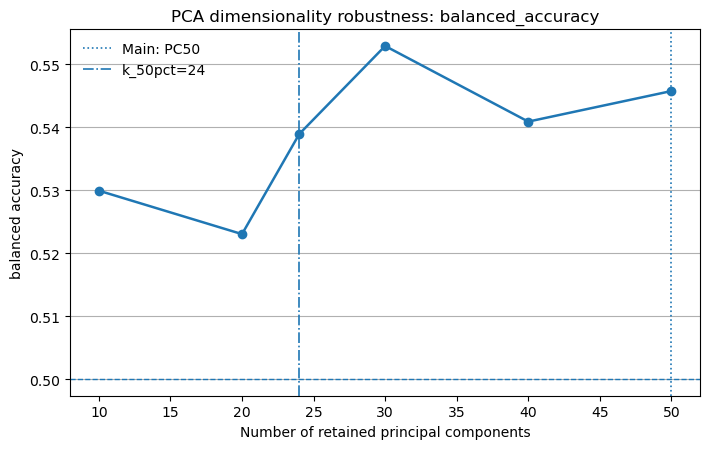

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_dimensionality_balanced_accuracy.png


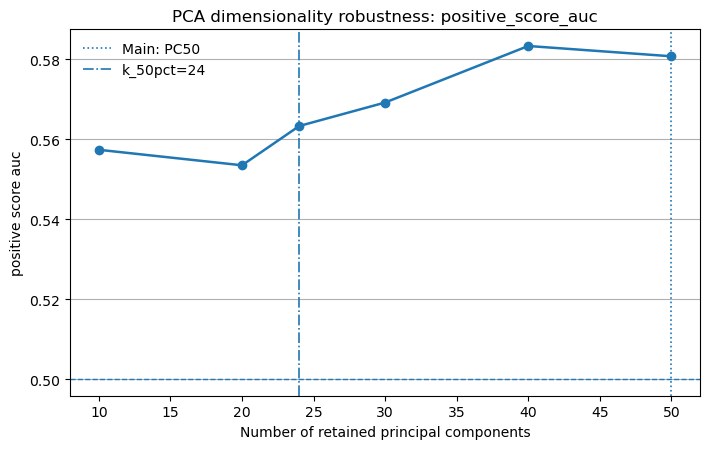

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_dimensionality_positive_score_auc.png


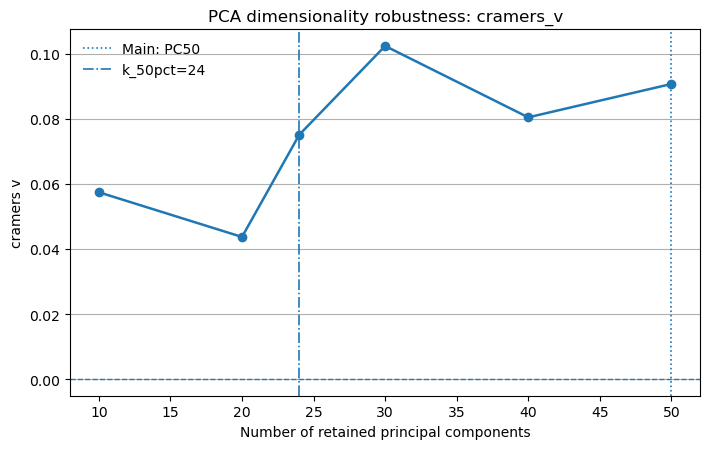

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_dimensionality_cramers_v.png


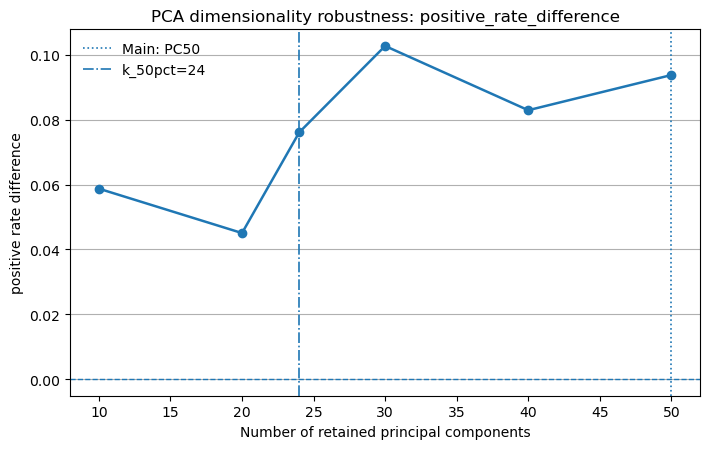

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_dimensionality_positive_rate_difference.png


In [10]:
# ============================================================
# 8.1 Dimensionality robustness plots
# ============================================================

metrics_to_plot = [
    ("balanced_accuracy", 0.5),
    ("positive_score_auc", 0.5),
    ("cramers_v", 0.0),
    ("positive_rate_difference", 0.0),
]

for metric, reference in metrics_to_plot:
    fig, ax = plt.subplots(figsize=(7.2, 4.6))

    ax.plot(
        DIMENSIONALITY_RESULTS["n_pcs"],
        DIMENSIONALITY_RESULTS[metric],
        marker="o",
        linewidth=1.8,
    )
    ax.axhline(reference, linestyle="--", linewidth=1.0)
    ax.axvline(MAIN_PC_N, linestyle=":", linewidth=1.2, label="Main: PC50")

    if k_50pct != MAIN_PC_N:
        ax.axvline(
            k_50pct,
            linestyle="-.",
            linewidth=1.2,
            label=f"k_50pct={k_50pct}",
        )

    ax.set_xlabel("Number of retained principal components")
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_title(f"PCA dimensionality robustness: {metric}")
    ax.grid(True, axis="y", linewidth=0.8)
    ax.legend(frameon=False)

    fig.tight_layout()
    out_path = OUT_DIR / f"GMM_validation_dimensionality_{metric}.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", out_path)


## 9. Validation 3 — Does the result depend on the specific participant sample?

This analysis tests **full-pipeline sample stability**. In each repetition, 80%
of participants are sampled without replacement **within each IAT group** to
preserve the original group composition. Within that subsample, the complete
unsupervised connectomic pipeline is re-estimated:

1. nuisance residualization of FC edges;
2. removal of non-informative edges and edge-wise standardization;
3. PCA refitting using PC1–PC50;
4. PC-score standardization; and
5. refitting of the same two-component full-covariance GMM.

IAT labels are not used in any of these fitting steps. After clustering,
alignment with IAT groups is quantified within the subsample. In addition, the
subsample GMM labels are compared with the full-sample reference GMM labels for
the same participants using adjusted Rand index (ARI), which is invariant to
arbitrary cluster-number switching.

No permutation test is repeated inside each subsample; this section evaluates
stability of the estimated connectomic structure rather than repeated
significance testing.


In [11]:
# ============================================================
# 9. Validation 3: stratified 80% full-pipeline subsampling
# ============================================================

# Reference full-sample PC1-PC50 GMM, matched to the main analysis.
reference_out = fit_gmm_alignment(
    Z=Z_main,
    y_binary=y_group,
    random_state=RANDOM_STATE,
    run_permutation=False,
)

reference_labels = np.asarray(reference_out["labels"], dtype=int)
REFERENCE_METRICS = pd.DataFrame([reference_out["metrics"]])
display(REFERENCE_METRICS)

idx_low = np.flatnonzero(y_group == 0)
idx_high = np.flatnonzero(y_group == 1)

n_low_sub = max(2, int(np.floor(SUBSAMPLE_FRACTION * idx_low.size)))
n_high_sub = max(2, int(np.floor(SUBSAMPLE_FRACTION * idx_high.size)))

print(
    f"Each subsample: lowIAT={n_low_sub}/{idx_low.size}, "
    f"highIAT={n_high_sub}/{idx_high.size}, "
    f"total={n_low_sub + n_high_sub}/{len(y_group)}"
)


def one_subsample(rep):
    rng = np.random.default_rng(RANDOM_STATE + 100_000 + rep)

    # Stratified sampling preserves the low/high-IAT composition but does not
    # use the labels in PCA or GMM fitting.
    low_take = rng.choice(idx_low, size=n_low_sub, replace=False)
    high_take = rng.choice(idx_high, size=n_high_sub, replace=False)
    idx = np.sort(np.concatenate([low_take, high_take]))

    FC_sub = np.asarray(FC_model[idx, :], dtype=np.float32)
    cov_sub = np.asarray(covariates[idx, :], dtype=float)
    y_sub = np.asarray(y_group[idx], dtype=int)

    # 1) Re-estimate nuisance adjustment inside the subsample.
    C_sub = _design_matrix(cov_sub, FC_sub.shape[0])
    FC_resid_sub, _ = _residualize_with_C(FC_sub, C_sub)
    FC_resid_sub = np.asarray(FC_resid_sub, dtype=np.float32)

    # 2) Re-estimate feature filtering and edge-wise standardization.
    keep_sub = _select_finite_variance_columns(FC_resid_sub, eps=1e-8)
    FC_keep_sub = FC_resid_sub[:, keep_sub]

    if FC_keep_sub.shape[1] < MAIN_PC_N:
        raise RuntimeError(
            f"Subsample {rep}: only {FC_keep_sub.shape[1]} informative edges, "
            f"fewer than MAIN_PC_N={MAIN_PC_N}."
        )

    edge_mean_sub = FC_keep_sub.mean(axis=0, keepdims=True)
    edge_sd_sub = FC_keep_sub.std(axis=0, keepdims=True)
    edge_sd_sub[edge_sd_sub < 1e-8] = 1.0
    FC_z_sub = (FC_keep_sub - edge_mean_sub) / edge_sd_sub

    # 3) Refit PCA inside the subsample using exactly PC1-PC50.
    pca_sub = PCA(
        n_components=MAIN_PC_N,
        svd_solver="randomized",
        random_state=RANDOM_STATE,
    )
    scores_sub = pca_sub.fit_transform(FC_z_sub)

    # 4) Match the main analysis by standardizing each retained PC score.
    Z_sub = StandardScaler().fit_transform(scores_sub)

    # 5) Refit GMM. The same seed is used in every repetition so that
    # variation is driven primarily by the participant subsample, not by
    # deliberately changing the initialization seed.
    gmm = GaussianMixture(
        n_components=GMM_N_COMPONENTS,
        covariance_type=GMM_COVARIANCE_TYPE,
        n_init=GMM_N_INIT,
        reg_covar=GMM_REG_COVAR,
        max_iter=GMM_MAX_ITER,
        random_state=RANDOM_STATE,
    )
    labels_sub = gmm.fit_predict(Z_sub)
    probs_sub = gmm.predict_proba(Z_sub).astype(float)

    metrics, _, _, _, _ = evaluate_binary_cluster_alignment(
        labels=labels_sub,
        y_binary=y_sub,
        clustering_scores=probs_sub,
    )

    # ARI is invariant to arbitrary cluster 0/1 switching.
    reference_ari = float(
        adjusted_rand_score(reference_labels[idx], labels_sub)
    )

    return {
        "rep": rep,
        "n_subjects": int(idx.size),
        "n_lowIAT": int(np.sum(y_sub == 0)),
        "n_highIAT": int(np.sum(y_sub == 1)),
        "n_edges_kept": int(np.sum(keep_sub)),
        "pca50_cumulative_variance": float(
            np.sum(pca_sub.explained_variance_ratio_)
        ),
        "reference_cluster_ARI": reference_ari,
        "gmm_converged": bool(gmm.converged_),
        "gmm_n_iter": int(gmm.n_iter_),
        "balanced_accuracy": float(metrics["balanced_accuracy"]),
        "positive_score_auc": float(metrics["positive_score_auc"]),
        "cramers_v": float(metrics["cramers_v"]),
        "ARI_IAT": float(metrics["ARI"]),
        "NMI_IAT": float(metrics["NMI"]),
        "positive_rate_difference": float(metrics["positive_rate_difference"]),
    }


subsample_rows = Parallel(
    n_jobs=N_JOBS_SUBSAMPLE,
    backend="threading",
    verbose=5,
)(
    delayed(one_subsample)(rep)
    for rep in range(N_SUBSAMPLES)
)

SUBSAMPLE_RESULTS = pd.DataFrame(subsample_rows)

subsample_path = OUT_DIR / "GMM_validation_subsampling_distribution.csv"
SUBSAMPLE_RESULTS.to_csv(subsample_path, index=False)
print("Saved:", subsample_path)

display(SUBSAMPLE_RESULTS.head())


,cluster_positive_like,cluster_negative_like,positive_rate_difference,accuracy,balanced_accuracy,positive_score_auc,cramers_v,chi2_p,fisher_p,ARI,NMI,gmm_converged,gmm_n_iter,gmm_lower_bound
0,1,0,0.09381,0.524237,0.545708,0.580787,0.09073,0.00246,0.002166,-0.000093,0.006427,True,40,-69.061611


Each subsample: lowIAT=522/653, highIAT=368/461, total=890/1114


[Parallel(n_jobs=18)]: Using backend ThreadingBackend with 18 concurrent workers.
[Parallel(n_jobs=18)]: Done  36 tasks      | elapsed:   47.8s
[Parallel(n_jobs=18)]: Done 126 tasks      | elapsed:  2.6min
[Parallel(n_jobs=18)]: Done 252 tasks      | elapsed:  4.9min
[Parallel(n_jobs=18)]: Done 414 tasks      | elapsed:  7.9min


Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_subsampling_distribution.csv


[Parallel(n_jobs=18)]: Done 500 out of 500 | elapsed:  9.4min finished


,rep,n_subjects,n_lowIAT,n_highIAT,n_edges_kept,pca50_cumulative_variance,reference_cluster_ARI,gmm_converged,gmm_n_iter,balanced_accuracy,positive_score_auc,cramers_v,ARI_IAT,NMI_IAT,positive_rate_difference
0,0,890,522,368,22791,0.586979,0.312275,True,59,0.554416,0.585580,0.105048,0.008179,0.008439,0.105855
1,1,890,522,368,22791,0.588114,0.431710,True,53,0.519152,0.538301,0.036093,-0.002103,0.001093,0.038530
2,2,890,522,368,22791,0.587711,0.403778,True,103,0.543145,0.569936,0.082742,0.005076,0.005284,0.083778
3,3,890,522,368,22791,0.589393,0.272762,True,114,0.546690,0.559421,0.090409,0.011094,0.006298,0.092042
4,4,890,522,368,22791,0.590554,0.497054,True,69,0.551318,0.583000,0.099386,0.005125,0.007607,0.100735


In [12]:
# ============================================================
# 9.1 Subsampling stability summary
# ============================================================

stability_metrics = [
    "pca50_cumulative_variance",
    "reference_cluster_ARI",
    "balanced_accuracy",
    "positive_score_auc",
    "cramers_v",
    "ARI_IAT",
    "NMI_IAT",
    "positive_rate_difference",
]

summary_rows = []

for metric in stability_metrics:
    s = summarize_distribution(SUBSAMPLE_RESULTS[metric])
    summary_rows.append({"metric": metric, **s})

SUBSAMPLE_SUMMARY = pd.DataFrame(summary_rows)

# Additional interpretable stability proportions.
extra_summary = pd.DataFrame(
    [
        {
            "metric": "proportion_balanced_accuracy_above_chance",
            "mean": float(np.mean(SUBSAMPLE_RESULTS["balanced_accuracy"] > 0.5)),
            "sd": np.nan,
            "median": np.nan,
            "p2_5": np.nan,
            "p97_5": np.nan,
        },
        {
            "metric": "proportion_auc_above_chance",
            "mean": float(np.mean(SUBSAMPLE_RESULTS["positive_score_auc"] > 0.5)),
            "sd": np.nan,
            "median": np.nan,
            "p2_5": np.nan,
            "p97_5": np.nan,
        },
        {
            "metric": "proportion_positive_rate_difference_positive",
            "mean": float(np.mean(SUBSAMPLE_RESULTS["positive_rate_difference"] > 0)),
            "sd": np.nan,
            "median": np.nan,
            "p2_5": np.nan,
            "p97_5": np.nan,
        },
        {
            "metric": "proportion_GMM_converged",
            "mean": float(np.mean(SUBSAMPLE_RESULTS["gmm_converged"])),
            "sd": np.nan,
            "median": np.nan,
            "p2_5": np.nan,
            "p97_5": np.nan,
        },
    ]
)

SUBSAMPLE_SUMMARY = pd.concat(
    [SUBSAMPLE_SUMMARY, extra_summary],
    ignore_index=True,
)

display(SUBSAMPLE_SUMMARY)

summary_path = OUT_DIR / "GMM_validation_subsampling_summary.csv"
SUBSAMPLE_SUMMARY.to_csv(summary_path, index=False)
print("Saved:", summary_path)


,metric,mean,sd,median,p2_5,p97_5
0,pca50_cumulative_variance,0.588735,0.003596,0.588911,0.581374,0.595302
1,reference_cluster_ARI,0.370892,0.111746,0.389106,0.009508,0.526593
2,balanced_accuracy,0.539638,0.015388,0.540735,0.502479,0.565546
3,positive_score_auc,0.565158,0.019032,0.568475,0.502479,0.591433
4,cramers_v,0.077348,0.029847,0.079051,0.008693,0.129538
5,ARI_IAT,0.002682,0.005398,0.001365,-0.003800,0.016535
6,NMI_IAT,0.005384,0.003400,0.004921,0.000226,0.012978
7,positive_rate_difference,0.083001,0.030956,0.083130,0.022670,0.138842
8,proportion_balanced_accuracy_above_chance,1.000000,NaN,NaN,NaN,NaN
9,proportion_auc_above_chance,0.996000,NaN,NaN,NaN,NaN


Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_subsampling_summary.csv


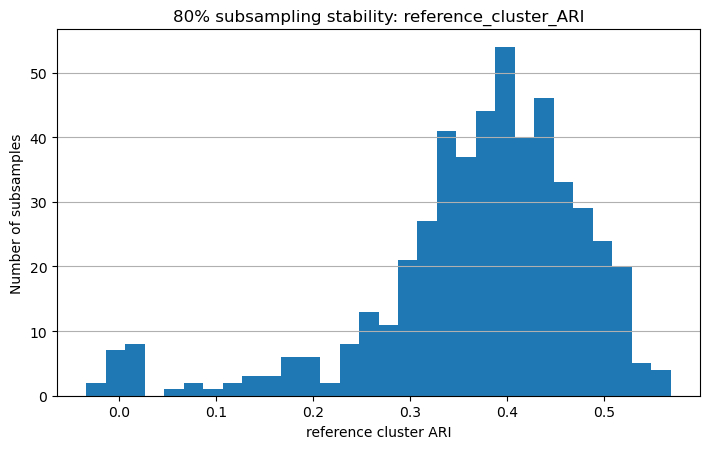

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_subsampling_reference_cluster_ARI.png


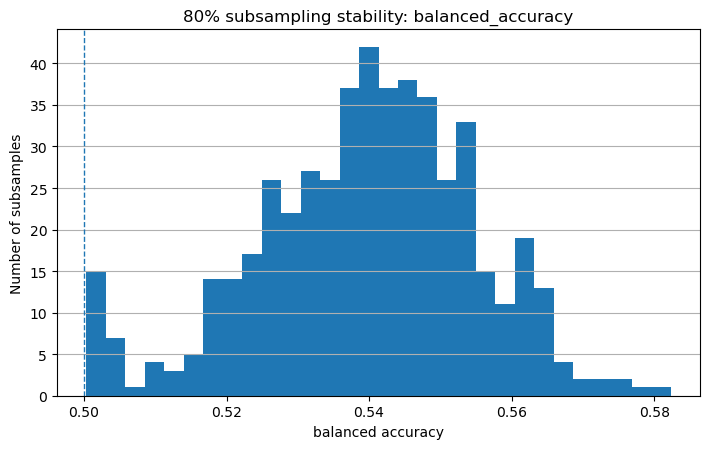

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_subsampling_balanced_accuracy.png


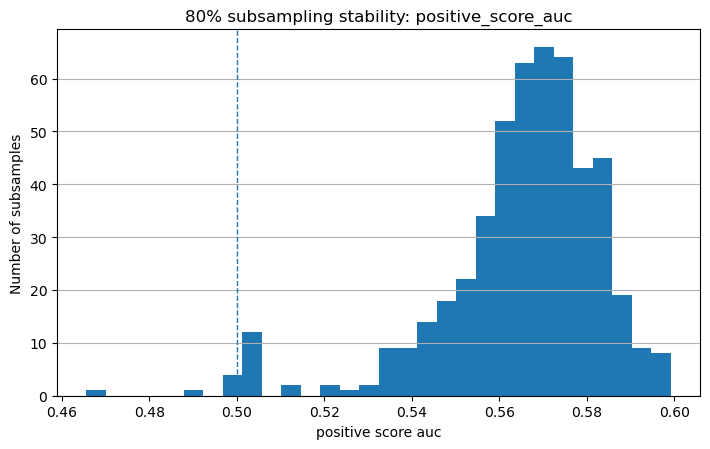

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_subsampling_positive_score_auc.png


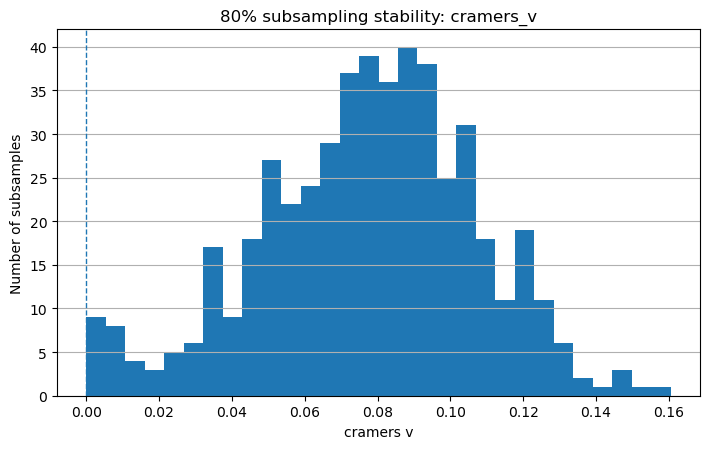

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_subsampling_cramers_v.png


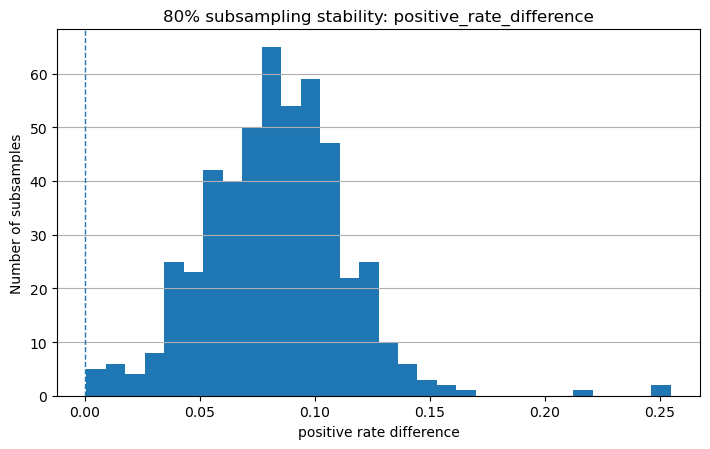

Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_subsampling_positive_rate_difference.png


In [13]:
# ============================================================
# 9.2 Subsampling stability plots
# ============================================================

plot_metrics = [
    ("reference_cluster_ARI", None),
    ("balanced_accuracy", 0.5),
    ("positive_score_auc", 0.5),
    ("cramers_v", 0.0),
    ("positive_rate_difference", 0.0),
]

for metric, reference in plot_metrics:
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    ax.hist(SUBSAMPLE_RESULTS[metric].dropna().to_numpy(), bins=30)

    if reference is not None:
        ax.axvline(reference, linestyle="--", linewidth=1.0)

    ax.set_xlabel(metric.replace("_", " "))
    ax.set_ylabel("Number of subsamples")
    ax.set_title(f"80% subsampling stability: {metric}")
    ax.grid(True, axis="y", linewidth=0.8)

    fig.tight_layout()
    out_path = OUT_DIR / f"GMM_validation_subsampling_{metric}.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", out_path)


## 10. Compact validation summary

This final table places the three validation questions side by side:

- **PC50 arbitrariness:** `k_50pct` and its formal GMM/permutation result;
- **dimensionality dependence:** range of effect-size estimates across the PC grid;
- **sample dependence:** distribution of alignment and reference-cluster ARI across
  80% subsamples.

Interpret the dimensionality and subsampling sections as robustness analyses,
not as additional searches for nominally significant results.


In [14]:
# ============================================================
# 10. Compact validation summary
# ============================================================

key_dim_metrics = [
    "balanced_accuracy",
    "positive_score_auc",
    "cramers_v",
    "positive_rate_difference",
]

validation_summary = {
    "main_pc_n": MAIN_PC_N,
    "main_pc50_cumulative_variance": main_cumvar,
    "k_50pct": k_50pct,
    "k_50pct_cumulative_variance": k50_cumvar,
    "k_50pct_balanced_accuracy": float(k50_metrics["balanced_accuracy"]),
    "k_50pct_auc": float(k50_metrics["positive_score_auc"]),
    "k_50pct_cramers_v": float(k50_metrics["cramers_v"]),
    "k_50pct_positive_rate_difference": float(
        k50_metrics["positive_rate_difference"]
    ),
    "k_50pct_perm_p_balanced_accuracy": float(
        k50_metrics["perm_p_balanced_accuracy"]
    ),
    "k_50pct_perm_p_auc": float(
        k50_metrics["perm_p_positive_score_auc"]
    ),
    "k_50pct_perm_p_cramers_v": float(
        k50_metrics["perm_p_cramers_v"]
    ),
}

for metric in key_dim_metrics:
    validation_summary[f"dimension_curve_{metric}_min"] = float(
        DIMENSIONALITY_RESULTS[metric].min()
    )
    validation_summary[f"dimension_curve_{metric}_max"] = float(
        DIMENSIONALITY_RESULTS[metric].max()
    )

for metric in [
    "reference_cluster_ARI",
    "balanced_accuracy",
    "positive_score_auc",
    "cramers_v",
    "positive_rate_difference",
]:
    validation_summary[f"subsampling_{metric}_median"] = float(
        SUBSAMPLE_RESULTS[metric].median()
    )
    validation_summary[f"subsampling_{metric}_p2_5"] = float(
        SUBSAMPLE_RESULTS[metric].quantile(0.025)
    )
    validation_summary[f"subsampling_{metric}_p97_5"] = float(
        SUBSAMPLE_RESULTS[metric].quantile(0.975)
    )

VALIDATION_SUMMARY = pd.DataFrame([validation_summary])
display(VALIDATION_SUMMARY.T)

final_path = OUT_DIR / "GMM_validation_key_summary.csv"
VALIDATION_SUMMARY.to_csv(final_path, index=False)
print("Saved:", final_path)


,0
main_pc_n,50.000000
main_pc50_cumulative_variance,0.582415
k_50pct,24.000000
k_50pct_cumulative_variance,0.504057
k_50pct_balanced_accuracy,0.538891
k_50pct_auc,0.563337
k_50pct_cramers_v,0.075124
k_50pct_positive_rate_difference,0.076135
k_50pct_perm_p_balanced_accuracy,0.011398
k_50pct_perm_p_auc,0.000600


Saved: /Users/fmri24/Desktop/YiZhang/CPM_GMM_validation/GMM_validation_key_summary.csv
